In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/kaggle/input/datasets/mirichoi0218/insurance/insurance.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
from sklearn.preprocessing import LabelEncoder 
le = LabelEncoder()

df['region']= le.fit_transform(df['region'])
df['smoker'] = le.fit_transform(df['smoker'])
df['sex'] = le.fit_transform(df['sex'])

In [5]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830
1334,18,0,31.920,0,0,0,2205.98080
1335,18,0,36.850,0,0,2,1629.83350
1336,21,0,25.800,0,0,3,2007.94500


<Axes: xlabel='bmi', ylabel='charges'>

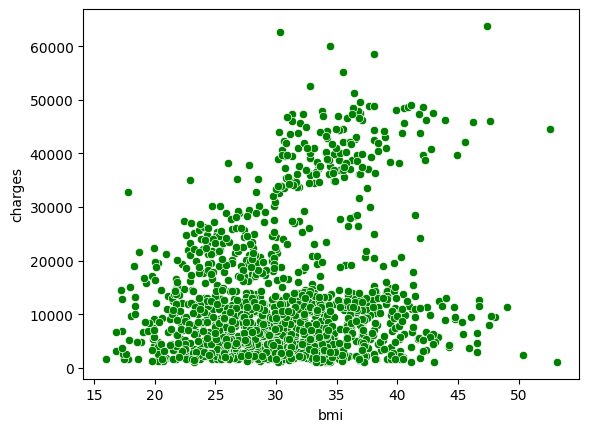

In [6]:
sns.scatterplot(x = df['bmi'], y = df['charges'], color = "green")

<Axes: xlabel='smoker', ylabel='charges'>

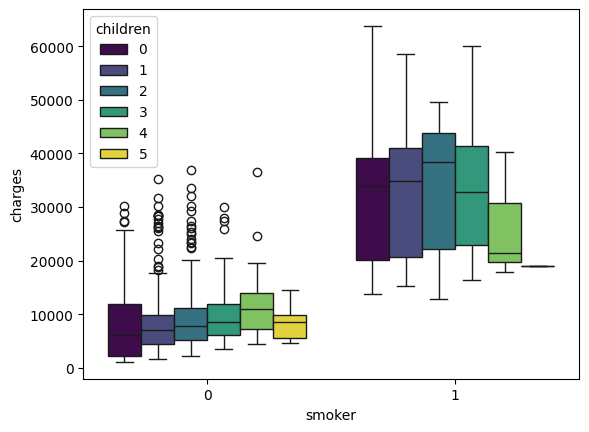

In [7]:
sns.boxplot(df,x = df['smoker'], y = df['charges'], palette = 'viridis', hue = df['children'])

<Axes: xlabel='region', ylabel='charges'>

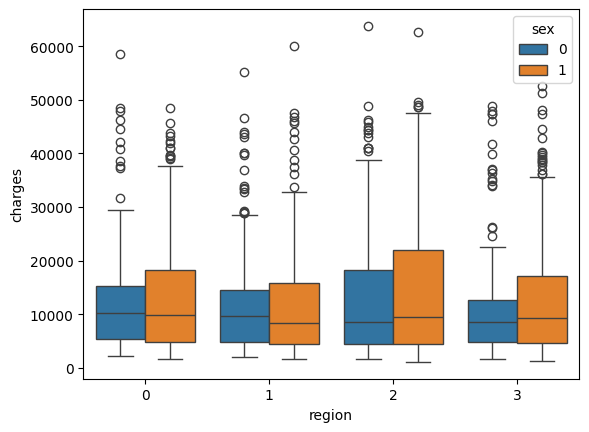

In [8]:
sns.boxplot(df, x = df['region'], y = df['charges'] , hue = df['sex'])

<Axes: xlabel='age', ylabel='charges'>

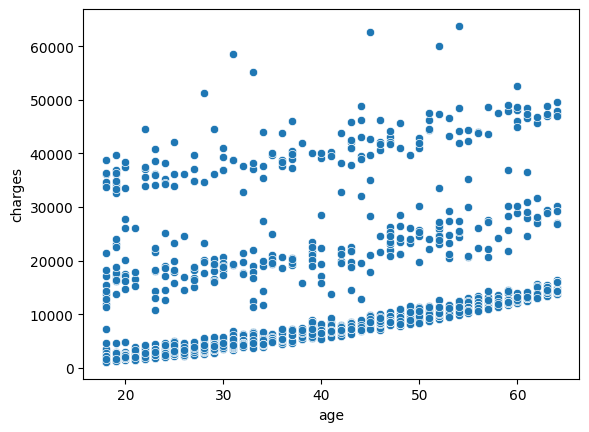

In [9]:
sns.scatterplot(df, x = df['age'], y = df['charges'])

In [10]:
X = df.drop(columns = ['charges'])
y = df.iloc[:, - 1]

In [11]:
from sklearn.model_selection import train_test_split 

X_train , X_test , y_train , y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

In [12]:
from sklearn.linear_model import LinearRegression 
lr = LinearRegression() 

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [13]:
from sklearn.metrics import r2_score , mean_absolute_error as mae, mean_squared_error as mse

print("Mean absoulte error: ", mae(y_pred, y_test))
print("Mean squared error:",  mse(y_pred, y_test))
print("R2 Score :", r2_score(y_pred, y_test))

Mean absoulte error:  4186.508898366433
Mean squared error: 33635210.431178406
R2 Score : 0.7086166433516328


/tmp/ipykernel_16/1319113370.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['charges'])


<Axes: xlabel='charges', ylabel='Density'>

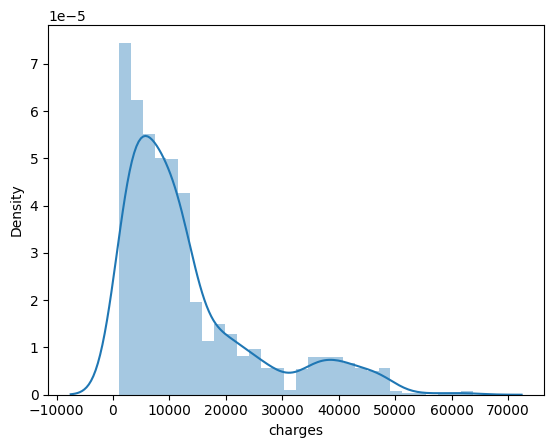

In [14]:
sns.distplot(df['charges'])

/tmp/ipykernel_16/2623977950.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['charge_log'])


<Axes: xlabel='charge_log', ylabel='Density'>

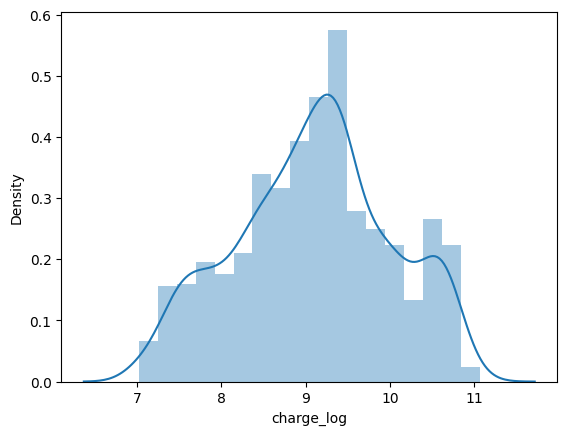

In [15]:
df['charge_log'] = np.log(df['charges'])
sns.distplot(df['charge_log'])

In [16]:
df

,age,sex,bmi,children,smoker,region,charges,charge_log
0,19,0,27.900,0,1,3,16884.92400,9.734176
1,18,1,33.770,1,0,2,1725.55230,7.453302
2,28,1,33.000,3,0,2,4449.46200,8.400538
3,33,1,22.705,0,0,1,21984.47061,9.998092
4,32,1,28.880,0,0,1,3866.85520,8.260197
...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830,9.268661
1334,18,0,31.920,0,0,0,2205.98080,7.698927
1335,18,0,36.850,0,0,2,1629.83350,7.396233
1336,21,0,25.800,0,0,3,2007.94500,7.604867
